# Training Rectified Flow for Data-to-Data Interpolation

This notebook implements a **training pipeline** for Rectified Flow on FashionMNIST data-to-data tasks

## Core Concept

A Rectified Flow learns a neural ODE velocity field that transports a source distribution to a target distribution. We optimize:

$$\mathcal{L} = \mathbb{E}_{t \sim U[0,1], x_a, x_b} \left[ \left\| v_\theta(z_t, t) - (x_b - x_a) \right\|^2 \right]$$

where:
- $z_t = (1-t) x_a + t x_b$ (straight-line path from source to target)
- $v_\theta$ is the learned velocity field (neural network)
- Target velocity is $(x_b - x_a)$

## Key Properties

1. **Straight-line interpolation**: Data points move linearly from source to target
2. **Velocity matching**: Network learns to predict exact endpoint transformation
3. **ODE sampling**: At test time, integrate velocity forward to generate trajectories


## Prerequisite: Colab Setup

Run all cells in [`00_colab_setup.ipynb`](00_colab_setup.ipynb) first. If you opened this notebook in a fresh Colab runtime, its import cell also locates or clones the repository before importing the project APIs.

In [5]:
# check environment
import os
import torch

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')
    print(f'CUDA: {torch.version.cuda}')

Device: cuda
GPU: NVIDIA A100-SXM4-80GB
CUDA: 13.0


In [6]:
# core imports
import json
import os
import subprocess
import sys
from pathlib import Path

runtime_root = Path.cwd().resolve()
search_roots = (runtime_root, *runtime_root.parents, Path('/content'))
bootstrap_candidates = tuple(
    candidate
    for root in search_roots
    for candidate in (root, root / 'minRF_interpolation')
)
repo_bootstrap = next((
    candidate.resolve()
    for candidate in bootstrap_candidates
    if (candidate / 'api' / 'flow_model_api.py').is_file()
), None)
if repo_bootstrap is None:
    repo_bootstrap = Path('/content/minRF_interpolation')
    if repo_bootstrap.exists() and any(repo_bootstrap.iterdir()):
        raise FileExistsError(
            f'Cannot clone into non-empty directory: {repo_bootstrap}. '
            'Remove or rename that incomplete directory, then rerun this cell.'
        )
    subprocess.run(
        ['git', 'clone', 'https://github.com/Felinchen76/minRF_interpolation.git', str(repo_bootstrap)],
        check=True,
    )
    repo_bootstrap = repo_bootstrap.resolve()
if str(repo_bootstrap) not in sys.path:
    sys.path.insert(0, str(repo_bootstrap))
repo_root = repo_bootstrap
os.environ.setdefault(
    'MINRF_RUNTIME_ROOT',
    str(runtime_root if runtime_root != repo_root else repo_root.parent),
)
os.chdir(repo_root)
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

# use project APIs
from api.flow_model_api import (
    DataToDataRF,
    build_flow_model,
)
from api.checkpoint_management import CheckpointManager
from api.training_api import TrainingSpec, train_data_to_data_flow

print('Imports successful')

Imports successful


In [7]:
# disable Weights & Biases (for clean training without external logging)
os.environ['WANDB_DISABLED'] = 'true'
print('W&B disabled')

W&B disabled


## Training Configuration


### FashionMNIST Dataset Overview

FashionMNIST contains 10 classes of clothing items. Default configuration trains on:

| Class ID | Name | Role in Training |
|----------|------|------------------|
| 0 | T-shirt/top | - |
| 1 | Trouser | - |
| 2 | Pullover | - |
| 3 | Dress | - |
| 4 | Coat | - |
| 5 | Sandal | - |
| 6 | Shirt | - |
| **7** | **Sneaker** | **Source (x_a)** |
| 8 | Bag | - |
| **9** | **Ankle Boot** | **Target (x_b)** |

**Interpolation Task**: Model learns to transport images from Sneaker class to Ankle Boot class.

This pairing was chosen because both are footwear with distinct visual features, making it a meaningful semantic transformation task


In [8]:
config = TrainingSpec(
    model_profile='medium',
    source_class=7,
    target_class=9,
    train_epochs=100,
    seed=42,
    deterministic=True,
    model_name='fmnist_d2d_training',
    load_best_if_available=False,
    checkpoint_every=20,  # set to 25 for checkpoints at epochs 25, 50, ...
    validation_fraction=0.1,  # held out from the training split, not the official test set
    mixed_precision=True,  # CUDA FP16 + gradient scaling, suitable for a T4
    resume_from=None,  # set to the latest or a numbered checkpoint to continue
)
output_dir = repo_root / 'contents'
print('Configuration created')
print(f'  Source class: {config.source_class} (Sneaker)')
print(f'  Target class: {config.target_class} (Ankle Boot)')
print(f'  Model: {config.model_profile}')
print(f'  Epochs (total target, including resumed epochs): {config.train_epochs}')
print(f'  Seed: {config.seed} (deterministic algorithms: {config.deterministic})')

Configuration created
  Source class: 7 (Sneaker)
  Target class: 9 (Ankle Boot)
  Model: medium
  Epochs (total target, including resumed epochs): 100
  Seed: 42 (deterministic algorithms: True)


## Data Loading

The API uses the official FashionMNIST training split for gradient updates and reserves a stratified 10% subset of it for validation and checkpoint selection. The official test split is not used during training.

In [9]:
print('The training API splits the official training data into train and validation subsets.')
print(f'Class pair: {config.source_class} -> {config.target_class}')
print(f'Batch size: {config.batch_size} train / {config.test_batch_size} validation')

The training API splits the official training data into train and validation subsets.
Class pair: 7 -> 9
Batch size: 128 train / 128 validation


## Model Initialization

In [10]:
print(f'Model profile: {config.model_profile}')
print('The training API constructs the model and optimizer via flow_model_api.')
print(f'CUDA mixed precision requested: {config.mixed_precision}')

Model profile: medium
The training API constructs the model and optimizer via flow_model_api.
CUDA mixed precision requested: True


## Training Loop

For each epoch:
1. **Forward pass**: $z_t = (1-t) x_a + t x_b$, predict $v_\theta(z_t, t)$
2. **Loss**: MSE between predicted and target velocity
3. **Backward pass**: Update model parameters
4. **Validation**: Evaluate on a held-out subset of the training split; track the best model
5. **Early stopping**: Stop if validation loss plateaus


In [11]:
print('Training entry point:', train_data_to_data_flow.__module__)
print(f'Numbered checkpoint interval: {config.checkpoint_every} epochs')

Training entry point: api.training_api
Numbered checkpoint interval: 20 epochs


In [12]:
# prepare checkpoint directory
checkpoint_dir = repo_root / 'assets' / 'fmnist_d2d_runs'
config.checkpoint_dir = str(checkpoint_dir)
output_dir.mkdir(parents=True, exist_ok=True)

checkpoint_manager = CheckpointManager(config.checkpoint_dir)

print(f'Checkpoints will be saved to: {checkpoint_dir}')

Checkpoints will be saved to: /content/minRF_interpolation/assets/fmnist_d2d_runs


In [13]:
result = train_data_to_data_flow(spec=config, device=device)
model = result['model']
model_spec = result['setup']['model_spec']
history = {'train_loss': result['train_history'], 'val_loss': result['val_history']}
best_val_loss = result['best_val_loss']
epoch_with_best = result['best_epoch'] - 1
checkpoint_best = result['best_path']
print(f'Model parameters: {sum(p.numel() for p in model.parameters()):,}')
print(f'Best validation loss: {best_val_loss:.6f} at epoch {epoch_with_best + 1}')

100%|██████████| 26.4M/26.4M [00:00<00:00, 113MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 3.94MB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 58.7MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 19.7MB/s]
/content/minRF_interpolation/api/training_api.py:244: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=amp_enabled)


Training on cuda (NVIDIA A100-SXM4-80GB) | AMP: True | batches: 42 train, 5 val
Epoch 1/100 | train=0.308368 | val=0.194329 | best=0.194329 @ 1 | train 7.7s, val 0.4s, save 0.2s
Epoch 2/100 | train=0.172827 | val=0.146478 | best=0.146478 @ 2 | train 4.9s, val 0.4s, save 0.2s
Epoch 3/100 | train=0.130432 | val=0.113643 | best=0.113643 @ 3 | train 4.9s, val 0.4s, save 0.2s
Epoch 4/100 | train=0.109325 | val=0.096760 | best=0.096760 @ 4 | train 4.9s, val 0.4s, save 0.2s
Epoch 5/100 | train=0.093858 | val=0.085704 | best=0.085704 @ 5 | train 4.9s, val 0.4s, save 0.2s
Epoch 6/100 | train=0.085457 | val=0.078634 | best=0.078634 @ 6 | train 4.9s, val 0.4s, save 0.2s
Epoch 7/100 | train=0.080243 | val=0.076011 | best=0.076011 @ 7 | train 4.9s, val 0.4s, save 0.2s
Epoch 8/100 | train=0.073859 | val=0.069670 | best=0.069670 @ 8 | train 4.9s, val 0.4s, save 0.2s
Epoch 9/100 | train=0.072537 | val=0.067528 | best=0.067528 @ 9 | train 4.9s, val 0.4s, save 0.2s
Epoch 10/100 | train=0.069129 | val=0.

## Training Summary

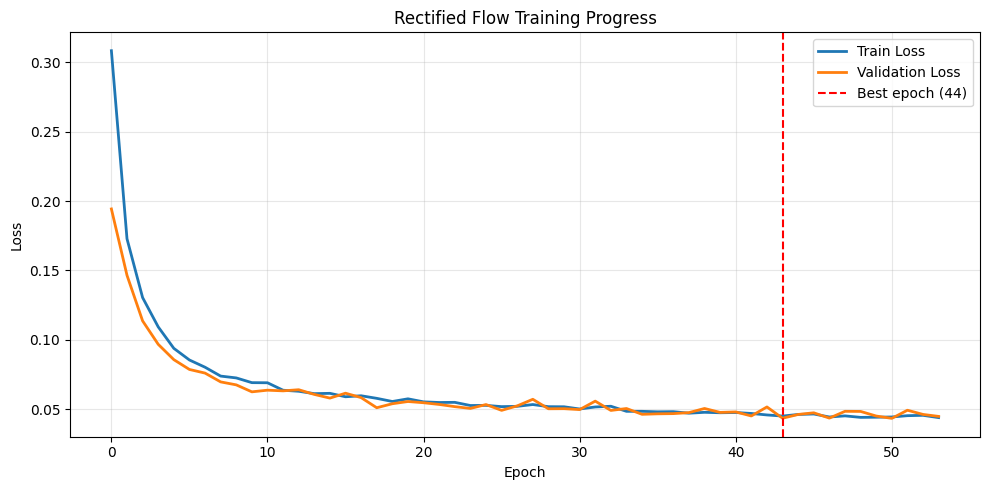

Training curve saved


In [14]:
import matplotlib.pyplot as plt

# plot training curves
plt.figure(figsize=(10, 5))
plt.plot(history['train_loss'], label='Train Loss', linewidth=2)
plt.plot(history['val_loss'], label='Validation Loss', linewidth=2)
plt.axvline(x=epoch_with_best, color='red', linestyle='--', label=f'Best epoch ({epoch_with_best+1})')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Rectified Flow Training Progress')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(output_dir / 'training_curves.png', dpi=150)
plt.show()

print(f'Training curve saved')

In [15]:
# save training history
history_file = output_dir / 'training_history.json'
with open(history_file, 'w') as f:
    json.dump(history, f, indent=2)

print(f'History saved to {history_file}')

History saved to /content/minRF_interpolation/contents/training_history.json


In [16]:
# print final statistics
print('\n' + '='*60)
print('TRAINING COMPLETED')
print('='*60)
print(f'Total epochs trained: {len(history["train_loss"])}')
print(f'Best epoch: {epoch_with_best + 1}')
print(f'Best validation loss: {best_val_loss:.6f}')
print(f'Final train loss: {history["train_loss"][-1]:.6f}')
print(f'Final validation loss: {history["val_loss"][-1]:.6f}')
print(f'\nCheckpoint saved: {checkpoint_best}')
print('='*60)


TRAINING COMPLETED
Total epochs trained: 54
Best epoch: 44
Best validation loss: 0.043487
Final train loss: 0.043934
Final validation loss: 0.044801

Checkpoint saved: /content/minRF_interpolation/assets/fmnist_d2d_runs/fmnist_d2d_training_checkpoint_best.pt


## Load Best Model for Evaluation


In [17]:
# load best checkpoint for subsequent evaluation
# recreate model and optimizer
best_model, _, best_optimizer = build_flow_model(model_spec)
best_model = best_model.to(device)

# load checkpoint state
checkpoint = checkpoint_manager.load_checkpoint(
    best_model, config.model_name, checkpoint_type='best', device=device,
    load_optimizer=True, optimizer=best_optimizer
)

best_flow_model = DataToDataRF(best_model)

print(f'Best model loaded from epoch {epoch_with_best + 1}')
print(f'Validation loss at that epoch: {best_val_loss:.6f}')

Best model loaded from epoch 44
Validation loss at that epoch: 0.043487
